# 2. Freeing Candidates

> **Overview.** With candidates drawn uniformly, fixed slots rarely hold the inputs an LTU needs, and the parent's
> weights will not always point to them. If each LTU frees the candidates that do not stand out and draws new inputs
> for their slots, can 160 LTUs with 100 slots do as well as the current method with 160 LTUs?

**Setup.** As in `1_fixed_slots.ipynb`, with candidates drawn uniformly. At each GROW check, every 1k steps, each LTU
also frees each candidate whose z-score is below $z_{low}$: its slot takes a new input, drawn uniformly from the inputs
in none of the LTU's slots, with fresh sums. A wrong input's z-score is about $|N(0, 1)|$ at any age, so $z_{low} = 1$
frees about 2/3 of the wrong candidates at each check, while a right input's z-score grows with the square root of its
age. $z_{low}$ = 0.5, 1 and 2.

Curves: the current method with 16 LTUs (the same state) and with 160 LTUs (the reference); 160 LTUs with 100 fixed
slots, the candidates drawn uniformly (notebook 1); and the same with freeing. Output noise of std 0.1 or 1. 5 seeds;
500k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 16                       # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # observation noise on each output: the lowest RMSE possible

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects a candidate whose z-score is above this
FAN_IN = 20                          # a new LTU first reads this many inputs, drawn by its parent's weights
LTUS = 160
SLOTS = 100                          # slots per LTU, connections and candidates: a tenth of the inputs
Z_LOWS = (0.5, 1.0, 2.0)             # GROW frees each candidate whose z-score is below z_low

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE, and between GROW checks
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps, each just after a pruning

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, noise_std, key):
    # One input and its targets, with N(0, noise_std^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    clean = target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0)
    return x, clean + noise_std * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

The learner of `1_fixed_slots.ipynb`, with candidates drawn uniformly, and with `grow` freeing candidates.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (LTUs,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # Each LTU has a row of slots, each holding an input (`inputs`): a connection where `reads` holds, else a candidate.
    # w['hidden'] is the LTUs' weights over [slots, 1 (the bias)]; w['output'] is the outputs' weights over [inputs (the
    # linear learner), LTUs, 1].
    w: dict                     # {'hidden': (LTUs, slots + 1), 'output': (N_OUTPUTS, N_INPUTS + LTUs + 1)}
    inputs: jax.Array           # (LTUs, slots): the input in each slot
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, LTUs): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    g_sum: jax.Array            # (LTUs, slots): each slot's sums of g = dL/dz * x and of g^2, since the slot was filled
    g_sq: jax.Array             # or its LTU last connected an input


def rewire(net, key, replaced, parent):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by LTU, goes on a random output, its parent.
    # Its first FAN_IN slots are connections to inputs drawn without replacement with probability proportional to the
    # square of the parent's linear weight on each if parent, uniformly otherwise (Gumbel top-k), with LeCun uniform
    # weights, taking the signs of its shadow weight times the parent's linear weights if parent, at step-size
    # FAST_STEP_SIZE. Its other slots are candidates, drawn uniformly. Its output weights are 0, and its statistics,
    # Autostep state and gradient sums fresh.
    n_ltus, n_slots = net.inputs.shape
    out_key, draw_key, uniform_key, w_key = jax.random.split(key, 4)
    sign = jnp.where(jnp.arange(n_ltus) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.randint(out_key, (n_ltus,), 0, N_OUTPUTS)
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    first = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    rest = jax.random.gumbel(uniform_key, scores.shape)
    inputs = jax.lax.top_k(jnp.where(first, jnp.inf, rest), n_slots)[1]          # the first FAN_IN slots: connections
    reads = jnp.broadcast_to(jnp.arange(n_slots) < FAN_IN, inputs.shape)
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * reads
    w = jnp.where(parent, jnp.abs(w) * jnp.sign(jnp.take_along_axis(parent_w, inputs, 1)), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(reads, jnp.zeros((n_ltus, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    r = replaced[:, None]
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((n_ltus, 1)), axis=1),
                                        'output': zeros['output']}),
                        inputs=jnp.where(r, inputs, net.inputs),
                        reads=jnp.where(r, jnp.append(reads, jnp.ones((n_ltus, 1), bool), axis=1), net.reads),
                        opt=opt, stats=stats, shadow=shadow,
                        g_sum=jnp.where(r, 0.0, net.g_sum), g_sq=jnp.where(r, 0.0, net.g_sq))


def init_net(key, n_ltus, n_slots):
    # n_ltus new LTUs with n_slots slots each, reading random inputs with random signs (their parents have no weights
    # yet).
    w = {'hidden': jnp.zeros((n_ltus, n_slots + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + n_ltus + 1))}
    net = Net(w, jnp.zeros((n_ltus, n_slots), int), jnp.zeros((n_ltus, n_slots + 1), bool), OPTIMIZER.init(w),
              Stats(jnp.full(n_ltus, 0.5), jnp.zeros(n_ltus), jnp.zeros(n_ltus)), jnp.zeros((N_OUTPUTS, n_ltus)),
              jnp.zeros((n_ltus, n_slots)), jnp.zeros((n_ltus, n_slots)))
    return rewire(net, key, jnp.ones(n_ltus, bool), False)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and its prediction for this sample, made before learning from it, and adds g = dL/dz * x
    # and g^2 to each slot's sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.
    n_ltus = net.inputs.shape[0]
    slot_x = jnp.append(x[net.inputs], jnp.ones((n_ltus, 1)), axis=1)      # each LTU's slot inputs and 1

    def loss_fn(w, probe):
        b = ltu(jnp.sum(w['hidden'] * net.reads * slot_x, 1) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                       jax.lax.stop_gradient(prediction))

    (loss, (source, h, mean, prediction)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(n_ltus),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': slot_x * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    g = dz[:, None] * slot_x[:, :-1]
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        g_sum=net.g_sum + g, g_sq=net.g_sq + g ** 2), prediction

def grow(net, key, z_low):
    # Each LTU whose largest candidate z-score, z = |sum g| / sqrt(sum g^2), is above GROW_Z connects that candidate, at
    # weight 0 with step-size FAST_STEP_SIZE, and restarts its sums. Each candidate with z below z_low is freed: its
    # slot takes a new input, drawn uniformly from the inputs in none of its slots, with fresh sums.
    n_ltus, n_slots = net.inputs.shape
    candidates = ~net.reads[:, :-1]
    z = jnp.where(candidates, jnp.abs(net.g_sum) / jnp.sqrt(jnp.maximum(net.g_sq, 1e-30)), 0.0)
    grows = jnp.max(z, 1) > GROW_Z
    new = (jnp.arange(n_slots) == jnp.argmax(z, 1)[:, None]) & grows[:, None]

    freed = candidates & (z < z_low)
    kept = jnp.zeros((n_ltus, N_INPUTS), int).at[jnp.arange(n_ltus)[:, None], net.inputs].add(~freed * 1) > 0
    scores = jax.random.gumbel(key, kept.shape)
    drawn = jax.lax.top_k(jnp.where(kept, -jnp.inf, scores), n_slots)[1]
    inputs = jnp.where(freed, jnp.take_along_axis(drawn, jnp.maximum(jnp.cumsum(freed, 1) - 1, 0), 1), net.inputs)

    new = jnp.append(new, jnp.zeros((n_ltus, 1), bool), axis=1)
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    restart = freed | grows[:, None]
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, inputs=inputs,
                        reads=net.reads | new, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        g_sum=jnp.where(restart, 0.0, net.g_sum), g_sq=jnp.where(restart, 0.0, net.g_sq))


def prune(net, signs):
    # Each LTU stops reading every input whose weight's sign differs from `signs`, its sign at the last pruning (0 for
    # inputs read since); the bias stays. A cut input stays in its slot as a candidate, with fresh sums; its weight and
    # Autostep state are reset.
    cut = net.reads[:, :-1] & (signs != 0) & (jnp.sign(net.w['hidden'][:, :-1]) != signs)
    cut_all = jnp.append(cut, jnp.zeros((cut.shape[0], 1), bool), axis=1)
    zero = lambda t: {**t, 'hidden': jnp.where(cut_all, 0.0, t['hidden'])}
    beta = jnp.where(cut_all, net.opt.init_beta, net.opt.beta['hidden'])
    opt = net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v))
    return net._replace(w=zero(net.w), reads=net.reads & ~cut_all, opt=opt,
                        g_sum=jnp.where(cut, 0.0, net.g_sum), g_sq=jnp.where(cut, 0.0, net.g_sq))


def search(net, key):
    # The weakest 1 in 8 LTUs, by sum of |output weights|, become new LTUs. Returns the network and the LTUs replaced.
    strength = jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
    replaced = jnp.argsort(jnp.argsort(strength)) < strength.shape[0] // 8
    return rewire(net, key, replaced, True), replaced

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, noise_std, z_low):
    # NUM_STEPS online network-Autostep steps on samples from `target` with noise_std. After every WINDOW steps, GROW;
    # every PERIOD steps the LTUs are pruned, then searched, and the signs of the weights recorded (0 for the new
    # LTUs'). Returns each window's mean squared error.
    def window(carry, inputs):
        net, signs = carry
        index, key = inputs
        grow_key, search_key, key = jax.random.split(key, 3)

        def step(net, key):
            x, y = sample(target, noise_std, key)
            net, prediction = learn(net, x, y)
            return net, jnp.mean((prediction - y) ** 2)

        net, mse = jax.lax.scan(step, net, jax.random.split(key, WINDOW))
        net = grow(net, grow_key, z_low)
        due = (index + 1) * WINDOW % PERIOD == 0
        searched, new = search(prune(net, signs), search_key)
        net = pick(due, searched, net)
        signs = jnp.where(due, jnp.sign(net.w['hidden'][:, :-1]) * net.reads[:, :-1] * ~new[:, None], signs)
        return (net, signs), mse.mean()

    n = NUM_STEPS // WINDOW
    start = (net, jnp.zeros_like(net.w['hidden'][:, :-1]))
    return jax.lax.scan(window, start, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (LTUs, slots, z_low) of configs at every noise std of NOISE_STDS and on N_SEEDS seeds; the runs
    # with the same numbers of LTUs and slots are vmapped together. Seed s gives every run the same target network and
    # samples. Returns {(config, noise std): the RMSE of each window, shaped (seed, window)}.
    rmse = {}
    for shape in dict.fromkeys(c[:2] for c in configs):
        runs = [(c, n) for c in configs if c[:2] == shape for n in NOISE_STDS]
        noise, z_low, seed = (jnp.array(v) for v in zip(*[(n, c[2], s) for c, n in runs for s in range(N_SEEDS)]))
        keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
        targets = jax.vmap(make_target)(keys(2))
        nets = jax.vmap(lambda key: init_net(key, *shape))(keys(0))
        mse = jax.jit(jax.vmap(train))(nets, keys(1), targets, noise, z_low)
        rmse.update(zip(runs, np.sqrt(np.asarray(mse).reshape(len(runs), N_SEEDS, -1))))
    return rmse

## Runs

In [6]:
SAME_STATE = (LTUS * SLOTS // N_INPUTS, N_INPUTS, 0.0)   # the current method: every input in a slot
REFERENCE = (LTUS, N_INPUTS, 0.0)
FIXED = (LTUS, SLOTS, 0.0)
FREEING = [(LTUS, SLOTS, z_low) for z_low in Z_LOWS]
started = perf_counter()
rmse = run([SAME_STATE, REFERENCE, FIXED, *FREEING])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

60 runs in 134s


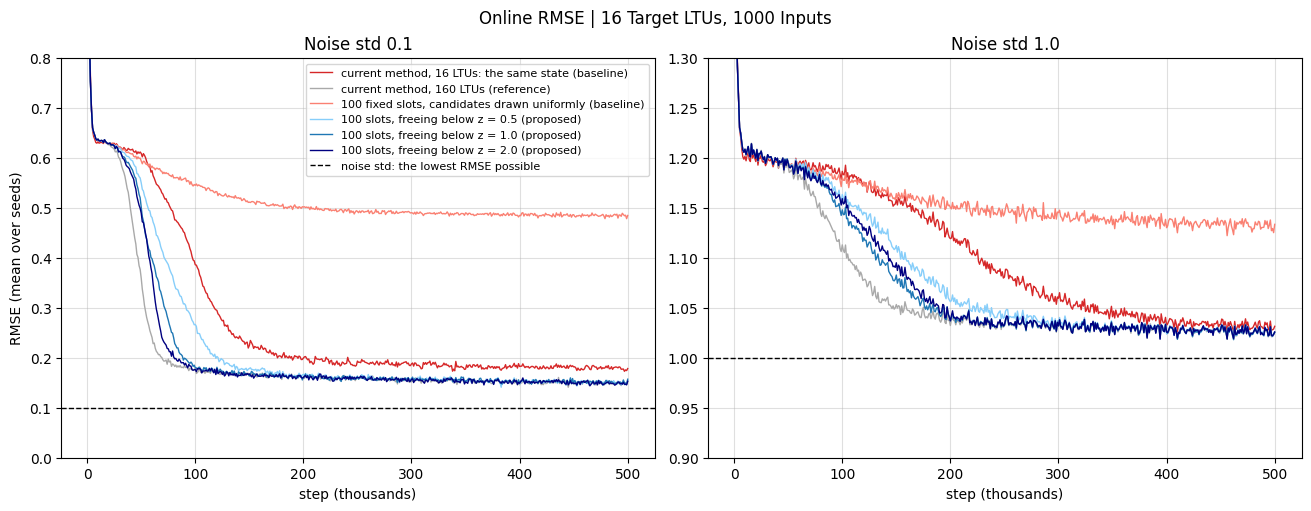

noise 0.1, RMSE over the last 100k steps: current method, 16 LTUs: the same state 0.181, current method, 160 LTUs 0.150, 100 fixed slots, candidates drawn uniformly 0.485, 100 slots, freeing below z = 0.5 0.151, 100 slots, freeing below z = 1.0 0.152, 100 slots, freeing below z = 2.0 0.151
noise 1.0, RMSE over the last 100k steps: current method, 16 LTUs: the same state 1.033, current method, 160 LTUs 1.026, 100 fixed slots, candidates drawn uniformly 1.134, 100 slots, freeing below z = 0.5 1.027, 100 slots, freeing below z = 1.0 1.027, 100 slots, freeing below z = 2.0 1.027


In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CURVES = [('current method, 16 LTUs: the same state (baseline)', SAME_STATE, 'tab:red'),
          ('current method, 160 LTUs (reference)', REFERENCE, 'darkgray'),
          ('100 fixed slots, candidates drawn uniformly (baseline)', FIXED, 'salmon'),
          *[(f'100 slots, freeing below z = {config[2]} (proposed)', config, color)
            for config, color in zip(FREEING, ['lightskyblue', 'tab:blue', 'navy'])]]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, noise, ylim in zip(axes, NOISE_STDS, [(0, 0.8), (0.9, 1.3)]):
    for label, config, color in CURVES:
        ax.plot(STEPS / 1000, rmse[config, noise].mean(0), color=color, lw=1, label=label)
    ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
    ax.set(title=f'Noise std {noise}', xlabel='step (thousands)', ylim=ylim)
    ax.grid(alpha=0.4)
axes[0].legend(fontsize=8)
axes[0].set_ylabel('RMSE (mean over seeds)')
fig.suptitle(f'Online RMSE | {N_TARGETS} Target LTUs, {N_INPUTS} Inputs')
plt.show()

last = 100_000 // WINDOW
for noise in NOISE_STDS:
    print(f'noise {noise}, RMSE over the last 100k steps: '
          + ', '.join(f'{label.split(" (")[0]} {rmse[config, noise][:, -last:].mean():.3f}' for label, config, _ in CURVES))

## Results

Freeing candidates closes the gap. At every $z_{low}$, 160 LTUs with 100 slots end level with the current method with
160 LTUs, and below the current method with the same state, at both noise levels. A higher $z_{low}$ frees more
candidates and learns faster at first. At $z_{low} = 2$, the LTUs learn almost as fast as with every input a candidate.